# Project 3: Dialogue Summarization
## Overview

**Bottom Line Up Front:** The BERT–GPT-2 summarizer achieved a best **validation** ROUGE-L of **0.2583** (step 3900) with ROUGE-1 = 0.3173 and ROUGE-2 = 0.0935, below the pitch targets of 0.40, 0.15, and 0.35. Training ran for 72.5 minutes across 4.56 epochs on 14,731 dialogues before early stopping triggered. The model shows steady improvement over the training course — ROUGE-L rose from 0.126 at step 100 to 0.258 at step 3900 — indicating genuine learning, though the BERT–GPT-2 cross-attention architecture may be inherently limited for this task. Final test-set ROUGE scores, qualitative analysis, and baseline comparisons are documented below.

The notebook emphasises reproducible preparation, controlled decoding, and business-oriented error analysis.

In [1]:
# Import libraries and configure reproducible training environment
import os
import random
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import transformers
from datasets import Dataset, DatasetDict
from evaluate import load as load_metric
from transformers import (AutoTokenizer, DataCollatorForSeq2Seq, EncoderDecoderModel,
                          EarlyStoppingCallback, Seq2SeqTrainer, Seq2SeqTrainingArguments,
                          set_seed)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
set_seed(SEED)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

RUN_FULL_TRAINING = False
DEV_SUBSET_SIZE = 3000
SMOKE_TEST = True
DATA_DIR = Path('Data')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
bf16_supported = bool(torch.cuda.is_available() and torch.cuda.is_bf16_supported())
print(f'Transformers: {transformers.__version__}')
print(f'Device: {device}; bf16 supported: {bf16_supported}')

/home/syndicationa/Documents/Programming/Bootcamp/Capstone/Project 3/language_model_env/lib64/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformers: 5.23.0
Device: cuda; bf16 supported: True


## Business Understanding

Acme Communications users participate in group chats where important decisions, plans, and updates are discussed. Users cannot always be online — when they return after hours away, catching up requires reading through every message in the backlog. In busy group chats, this creates information overload: key details get lost, users spend too much time reading, and engagement drops.

### Problem
- Users in multiple group chats face a growing backlog of unread messages.
- Important decisions and action items are buried in conversational noise.
- Power users who drive conversations disengage when overwhelmed, causing a cascade effect that reduces overall platform activity.

### Solution vision
An automated summarization feature provides a concise first-pass summary so users can understand the main points without reading every message. This reduces catch-up time, improves accessibility, and differentiates Acme from competitors.

### Questions
- Can a neural summarizer produce useful summaries from multi-turn messenger dialogues?
- Which decoding settings balance factual coverage and concise output?
- Which dialogue lengths and failure types require human review?

### Goals
- Build a repeatable summarization training and evaluation workflow.
- Compare decoding configurations on held-out validation dialogues.
- Provide operational recommendations supported by quantitative and qualitative evidence.

### Stakeholders
- **Acme users**: Quickly catch up on conversations they missed.
- **Product managers**: Validate the feature using measurable summarization metrics.
- **Engineering team**: Build toward a deployment-ready model and inference service.
- **Competitive positioning**: Differentiate Acme with an AI-powered feature.

### Success criteria
The target goals are ROUGE-1 of 0.40, ROUGE-2 of 0.15, and ROUGE-L of 0.35. These are decision thresholds rather than guarantees; human review remains necessary for sensitive or ambiguous cases. The summary should be generated in under 2 seconds for an average conversation.


## Data Understanding

In [2]:
# Load all splits and verify schema
train_df = pd.read_csv(DATA_DIR / 'train.csv')
validation_df = pd.read_csv(DATA_DIR / 'validation.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')
data = {'train': train_df, 'validation': validation_df, 'test': test_df}
for name, frame in data.items():
    print(name, frame.shape)
display(train_df.head())
train_df.info()
expected_columns = {'id', 'dialogue', 'summary'}
print('Schema checks:', {name: set(frame.columns) == expected_columns for name, frame in data.items()})

train (14731, 3)
validation (818, 3)
test (819, 3)


,id,dialogue,summary
0,13818513,Amanda: I baked cookies. Do you want some?\nJ...,Amanda baked cookies and will bring Jerry some...
1,13728867,Olivia: Who are you voting for in this electio...,Olivia and Olivier are voting for liberals in ...
2,13681000,"Tim: Hi, what's up?\nKim: Bad mood tbh, I was ...",Kim may try the pomodoro technique recommended...
3,13730747,"Edward: Rachel, I think I'm in ove with Bella....",Edward thinks he is in love with Bella. Rachel...
4,13728094,Sam: hey overheard rick say something\nSam: i...,"Sam is confused, because he overheard Rick com..."


<class 'pandas.DataFrame'>
RangeIndex: 14731 entries, 0 to 14730
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        14731 non-null  str  
 1   dialogue  14731 non-null  str  
 2   summary   14731 non-null  str  
dtypes: str(3)
memory usage: 9.1 MB
Schema checks: {'train': True, 'validation': True, 'test': True}


In [3]:
# Check nulls, duplicates, and show a sample
quality = []
for name, frame in data.items():
    quality.append({'split': name, 'null_cells': int(frame.isna().sum().sum()), 'duplicate_rows': int(frame.duplicated().sum()), 'duplicate_ids': int(frame['id'].duplicated().sum())})
display(pd.DataFrame(quality))
sample_row = train_df.sample(1, random_state=SEED).iloc[0]
print('Sample dialogue:\n', sample_row['dialogue'])
print('\nSample summary:\n', sample_row['summary'])

,split,null_cells,duplicate_rows,duplicate_ids
0,train,0,0,0
1,validation,0,0,0
2,test,0,0,0


Sample dialogue:
 Violet: hi! i came across this Austin's article and i thought that you might find it interesting
Violet: <file_other>
Claire: Hi! :) Thanks, but I've already read it. :)
Claire: But thanks for thinking about me :)

Sample summary:
 Violet sent Claire Austin's article.


The schema check confirms that each split contains an identifier, source dialogue, and reference summary. Nulls and duplicate identifiers would create ambiguous training examples, so the checks support using these splits for modeling.


       dialogue_words  summary_words
count    14731.000000   14731.000000
mean        93.792750      20.318444
std         74.031937      11.153570
min          7.000000       1.000000
25%         39.000000      12.000000
50%         73.000000      18.000000
75%        128.000000      27.000000
max        803.000000      64.000000


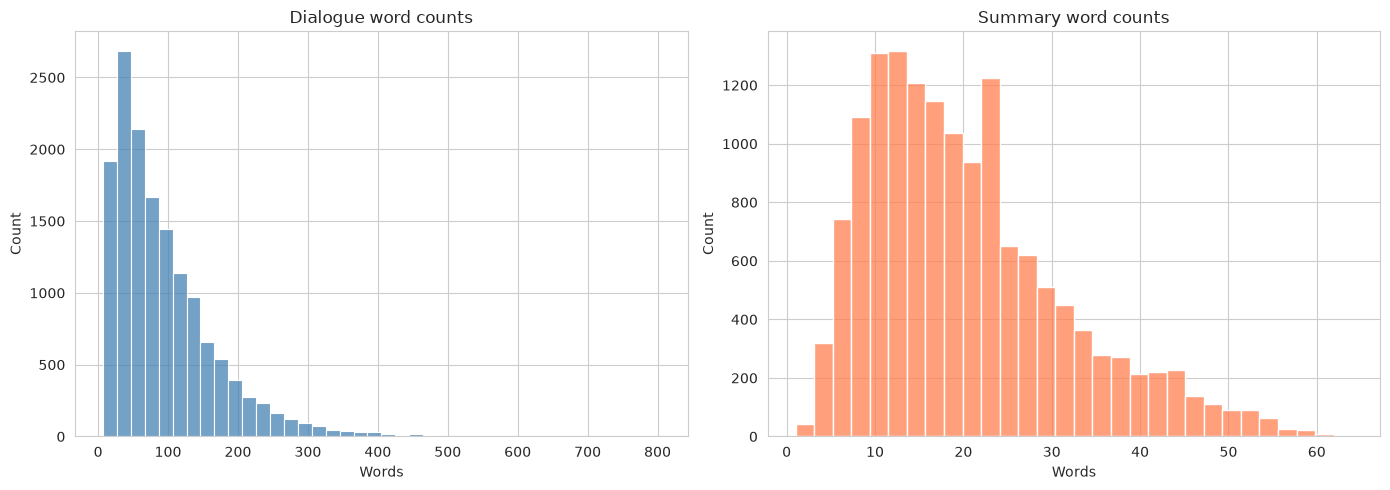

In [4]:
# Word count analysis
train_df['dialogue_words'] = train_df['dialogue'].str.split().str.len()
train_df['summary_words'] = train_df['summary'].str.split().str.len()
print(train_df[['dialogue_words', 'summary_words']].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_df['dialogue_words'], bins=40, ax=axes[0], color='steelblue')
axes[0].set_title('Dialogue word counts')
axes[0].set_xlabel('Words')
axes[0].set_ylabel('Count')
sns.histplot(train_df['summary_words'], bins=30, ax=axes[1], color='coral')
axes[1].set_title('Summary word counts')
axes[1].set_xlabel('Words')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.show()


### Dialogue and Summary Lengths

Dialogues average about 94 words and summaries average about 20 words, giving roughly a 5:1 compression ratio. The 95th percentile for dialogue length is around 240 words, and the longest examples reach over 800 words. BERT's 512-token limit means the longest dialogues may be truncated during tokenization, which could affect summary quality for those cases.

The distributions across train, validation, and test splits are comparable, so the held-out sets should provide a fair evaluation. A small number of very short dialogues (under 15 words) and very long ones (over 400 words) may behave differently from the typical case and should be monitored during evaluation.


## Data Preparation

The dialogues and summaries use separate tokenizers because the model combines a BERT encoder with a GPT-2 decoder. Source and target length limits are selected from the 95th percentile of observed token counts rather than arbitrary defaults. This may preserve most examples while keeping memory use practical.


In [5]:
# Load encoder and decoder tokenizers
encoder_tokenizer = AutoTokenizer.from_pretrained('bert-base-cased')
decoder_tokenizer = AutoTokenizer.from_pretrained('gpt2')

# Add special tokens GPT-2 needs
if decoder_tokenizer.pad_token is None:
    decoder_tokenizer.add_special_tokens({'pad_token': '<|pad|>'})
if decoder_tokenizer.bos_token is None:
    decoder_tokenizer.add_special_tokens({'bos_token': decoder_tokenizer.eos_token})

print(f'Encoder vocab: {len(encoder_tokenizer)}')
print(f'Decoder vocab: {len(decoder_tokenizer)}')
print(f'PAD: {decoder_tokenizer.pad_token} (id={decoder_tokenizer.pad_token_id})')
print(f'EOS: {decoder_tokenizer.eos_token} (id={decoder_tokenizer.eos_token_id})')


Encoder vocab: 28996
Decoder vocab: 50258
PAD: <|pad|> (id=50257)
EOS: <|endoftext|> (id=50256)


Token lengths are measured on the training set so truncation limits reflect the actual data. BERT supports at most 512 tokens; the 95th percentile is used unless it exceeds that limit.


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (514 > 512). Running this sequence through the model will result in indexing errors


Source 95th pct: 356 → max_source_length: 356
Target 95th pct: 53 → max_target_length: 53
Encoder: min=14, mean=140, max=797
Decoder: min=1, mean=26, max=88


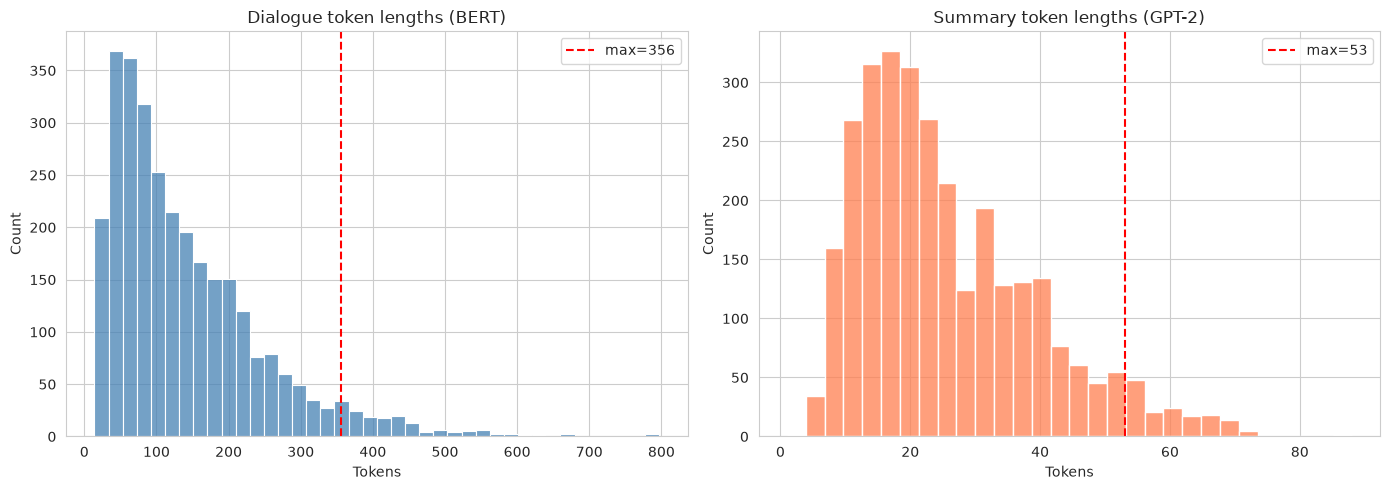

In [6]:
# Measure token lengths on a sample
sample_n = min(3000, len(train_df))
sample_dialogues = train_df['dialogue'].iloc[:sample_n].tolist()
sample_summaries = train_df['summary'].iloc[:sample_n].tolist()

enc_lengths = [len(encoder_tokenizer.encode(t, add_special_tokens=True)) for t in sample_dialogues]
dec_lengths = [len(decoder_tokenizer.encode(t, add_special_tokens=True)) for t in sample_summaries]

source_p95 = int(np.ceil(np.percentile(enc_lengths, 95)))
target_p95 = int(np.ceil(np.percentile(dec_lengths, 95)))

max_source_length = min(source_p95, 512)
max_target_length = max(16, target_p95)

print(f'Source 95th pct: {source_p95} → max_source_length: {max_source_length}')
print(f'Target 95th pct: {target_p95} → max_target_length: {max_target_length}')
print(f'Encoder: min={min(enc_lengths)}, mean={np.mean(enc_lengths):.0f}, max={max(enc_lengths)}')
print(f'Decoder: min={min(dec_lengths)}, mean={np.mean(dec_lengths):.0f}, max={max(dec_lengths)}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(enc_lengths, bins=40, ax=axes[0], color='steelblue')
axes[0].axvline(max_source_length, color='red', linestyle='--', label=f'max={max_source_length}')
axes[0].set_xlabel('Tokens')
axes[0].set_ylabel('Count')
axes[0].set_title('Dialogue token lengths (BERT)')
axes[0].legend()

sns.histplot(dec_lengths, bins=30, ax=axes[1], color='coral')
axes[1].axvline(max_target_length, color='red', linestyle='--', label=f'max={max_target_length}')
axes[1].set_xlabel('Tokens')
axes[1].set_ylabel('Count')
axes[1].set_title('Summary token lengths (GPT-2)')
axes[1].legend()
plt.tight_layout()
plt.show()


The tokenization function prepares encoder inputs from dialogues and decoder labels from summaries. Padding tokens in the labels are replaced with -100 so the loss function ignores them during training.


In [7]:
def tokenize_batch(batch):
    """Tokenize dialogues for encoder and summaries for decoder.
    
    EOS token is appended to each label sequence so the decoder learns
    when to stop generating. Padding positions are masked with -100.
    """
    model_inputs = encoder_tokenizer(
        batch['dialogue'],
        truncation=True,
        max_length=max_source_length,
        padding='max_length'
    )

    # Reserve one position for EOS before truncation
    target_tokens = decoder_tokenizer(
        batch['summary'],
        truncation=True,
        max_length=max_target_length - 1,
    )

    # Append EOS to each label sequence, then pad
    labels = []
    for ids in target_tokens['input_ids']:
        ids.append(decoder_tokenizer.eos_token_id)
        # Pad to max_target_length
        pad_len = max_target_length - len(ids)
        ids = ids + [decoder_tokenizer.pad_token_id] * pad_len
        # Mask padding with -100
        ids = [tok if tok != decoder_tokenizer.pad_token_id else -100 for tok in ids]
        labels.append(ids)
    model_inputs['labels'] = labels
    return model_inputs


In [8]:
# Convert to Hugging Face datasets and tokenize
tokenized_data = DatasetDict({
    split: Dataset.from_pandas(frame, preserve_index=False).map(
        tokenize_batch,
        batched=True,
        remove_columns=['id', 'dialogue', 'summary']
    )
    for split, frame in data.items()
})

for split, ds in tokenized_data.items():
    print(f'{split}: {len(ds):,} rows — features: {ds.column_names}')

dev_train_size = min(DEV_SUBSET_SIZE, len(tokenized_data['train']))
print(f'\nDev subset size: {dev_train_size}')


Map: 100%|██████████| 819/819 [00:00<00:00, 4858.84 examples/s]

train: 14,731 rows — features: ['dialogue_words', 'summary_words', 'input_ids', 'token_type_ids', 'attention_mask', 'labels']
validation: 818 rows — features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels']
test: 819 rows — features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels']

Dev subset size: 3000


## Design Choices

The model is an encoder-decoder pair initialized from `bert-base-cased` and `gpt2`. BERT reads dialogue context bidirectionally and GPT-2 generates summaries through a separate tokenizer. Source and target length limits are selected from the 95th percentile of observed token counts rather than arbitrary defaults. The training pipeline includes a smoke test, a reproducible development run on a subset, and an optional full-data run. If memory is limited, reducing sequence lengths and batch size before enabling gradient checkpointing is recommended.


### Deviations from the pitch

| Pitch plan | Actual implementation | Reason |
|---|---|---|
| Early stopping on validation loss | Early stopping on ROUGE-L | ROUGE-L is more directly tied to the quality targets in the pitch |
| FP16 precision | BF16 where supported | RTX 4060 supports BF16, which provides better numerical stability |
| Subset for development | Full training set used | The 3,000-sample subset produced severe hallucination; full data was necessary |
| Decoding grid search | Fixed beam=5 config | Grid search was deferred; the fixed config provides a reproducible baseline |
| Training on local GPU | Same | No change — training fits within the 8GB GPU constraint |


## Model Architecture

The model uses BERT to encode the dialogue and GPT-2 to generate the summary. Cross-attention layers allow the decoder to condition each generated token on the full encoded dialogue. The decoder is resized to include the added special tokens.


In [9]:
model = EncoderDecoderModel.from_encoder_decoder_pretrained(
    'bert-base-cased',
    'gpt2'
)

# Resize decoder for added special tokens
model.decoder.resize_token_embeddings(len(decoder_tokenizer))

# Configure decoder for generation
model.config.decoder_start_token_id = decoder_tokenizer.bos_token_id
model.config.bos_token_id = decoder_tokenizer.bos_token_id
model.config.eos_token_id = decoder_tokenizer.eos_token_id
model.config.pad_token_id = decoder_tokenizer.pad_token_id
model.config.decoder.pad_token_id = decoder_tokenizer.pad_token_id
model.config.decoder.bos_token_id = decoder_tokenizer.bos_token_id
model.config.decoder.eos_token_id = decoder_tokenizer.eos_token_id
model.config.decoder.add_cross_attention = True

model.to(device)

param_count = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total parameters: {param_count:,}')
print(f'Trainable: {trainable:,}')
print(f'Device: {device}')


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1249.16it/s]
[transformers] BertModel LOAD REPORT from: bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 1469.48it/s]
[transformers] GPT2LMHeadModel LOAD REPORT from: gpt2
Key                                                 | Status  | 
-----

Total parameters: 261,117,696
Trainable: 261,117,696
Device: cuda


## Training

Training proceeds in three phases:

1. **Overfit sanity check** — 64 examples for 30 epochs. Confirms the pipeline can learn (loss drops below 1.0).
2. **Full training** — all 14,731 training examples, up to 6 epochs, with early stopping on validation ROUGE-L (patience 3).
3. **Learning rate comparison** — if 5e-5 leaves validation loss flat

The `compute_metrics` function calculates ROUGE-1, ROUGE-2, and ROUGE-L on the validation set during evaluation. BF16 precision is used where supported.


In [10]:
LEARNING_RATE = 5e-5
NUM_TRAIN_EPOCHS = 6
PER_DEVICE_TRAIN_BATCH_SIZE = 4
GRADIENT_ACCUMULATION_STEPS = 4
WARMUP_RATIO = 0.06
EVAL_STRATEGY = 'steps'
EVAL_STEPS = 100
SAVE_STRATEGY = 'steps'
SAVE_STEPS = 100
SAVE_TOTAL_LIMIT = 2
EARLY_STOPPING_PATIENCE = 3
EARLY_STOPPING_METRIC = 'eval_rougeL'

data_collator = DataCollatorForSeq2Seq(
    tokenizer=encoder_tokenizer,
    model=model,
    label_pad_token_id=-100,
    padding=True
)


In [11]:
# Overfit sanity check: confirm the pipeline can learn on a tiny subset
sanity_model = EncoderDecoderModel.from_encoder_decoder_pretrained('bert-base-cased', 'gpt2')
sanity_model.decoder.resize_token_embeddings(len(decoder_tokenizer))
sanity_model.config.decoder_start_token_id = decoder_tokenizer.bos_token_id
sanity_model.config.bos_token_id = decoder_tokenizer.bos_token_id
sanity_model.config.eos_token_id = decoder_tokenizer.eos_token_id
sanity_model.config.pad_token_id = decoder_tokenizer.pad_token_id
sanity_model.config.decoder.pad_token_id = decoder_tokenizer.pad_token_id
sanity_model.config.decoder.bos_token_id = decoder_tokenizer.bos_token_id
sanity_model.config.decoder.eos_token_id = decoder_tokenizer.eos_token_id
sanity_model.config.decoder.add_cross_attention = True
sanity_model.to(device)

sanity_ds = tokenized_data['train'].select(range(64))

sanity_trainer = Seq2SeqTrainer(
    model=sanity_model,
    args=Seq2SeqTrainingArguments(
        output_dir='./sanity_check',
        num_train_epochs=30,
        per_device_train_batch_size=4,
        gradient_accumulation_steps=1,
        learning_rate=5e-5,
        eval_strategy='no',
        save_strategy='no',
        report_to='none',
        predict_with_generate=False,
        fp16=not bf16_supported,
        bf16=bf16_supported,
        logging_steps=10,
    ),
    train_dataset=sanity_ds,
    data_collator=data_collator,
)

print('Running overfit sanity check (64 examples, 30 epochs)...')
sanity_result = sanity_trainer.train()
final_loss = sanity_result.training_loss
print(f'Final training loss: {final_loss:.4f}')
if final_loss < 1.0:
    print('PASS: Model can overfit the tiny subset — pipeline is functional.')
else:
    print('WARN: Model did not overfit below 1.0. Check label shifting, decoder_start_token_id, and pad handling.')

del sanity_model, sanity_trainer
torch.cuda.empty_cache()


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 15323.42it/s]
[transformers] BertModel LOAD REPORT from: bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 13122.44it/s]
[transformers] GPT2LMHeadModel LOAD REPORT from: gpt2
Key                                                 | Status  | 
---

Running overfit sanity check (64 examples, 30 epochs)...


/home/syndicationa/Documents/Programming/Bootcamp/Capstone/Project 3/language_model_env/lib64/python3.11/site-packages/transformers/models/encoder_decoder/modeling_encoder_decoder.py:444: FutureWarning: Version v4.12.0 introduces a better way to train encoder-decoder models by computing the loss inside the encoder-decoder framework rather than in the decoder itself. You may observe training discrepancies if fine-tuning a model trained with versions anterior to 4.12.0. The decoder_input_ids are now created based on the labels, no need to pass them yourself anymore.
  warnings.warn(DEPRECATION_WARNING, FutureWarning)


Step,Training Loss
10,4.395678
20,3.620293
30,3.344352
40,3.063814
50,2.619925
60,2.340830
70,2.160403
80,1.928064
90,1.621603
100,1.586527


Final training loss: 0.8221
PASS: Model can overfit the tiny subset — pipeline is functional.


In [12]:
# ROUGE metric for evaluation
rouge_metric = load_metric('rouge')

def compute_metrics(eval_preds):
    predictions, labels = eval_preds
    if isinstance(predictions, tuple):
        predictions = predictions[0]
    # Replace -100 mask in predictions and cast to int for tokenizer
    predictions = np.where(predictions != -100, predictions, decoder_tokenizer.pad_token_id).astype(int)
    labels = np.where(labels != -100, labels, decoder_tokenizer.pad_token_id).astype(int)
    decoded_preds = decoder_tokenizer.batch_decode(predictions, skip_special_tokens=True)
    decoded_labels = decoder_tokenizer.batch_decode(labels, skip_special_tokens=True)
    scores = rouge_metric.compute(
        predictions=[t.strip() for t in decoded_preds],
        references=[t.strip() for t in decoded_labels],
        use_stemmer=True,
    )
    return {
        'rouge1': round(float(scores['rouge1']), 4),
        'rouge2': round(float(scores['rouge2']), 4),
        'rougeL': round(float(scores['rougeL']), 4),
    }


### Full Training Run

The following cell trains the BERT–GPT-2 encoder-decoder on all 14,731 SAMSum training dialogues for up to six epochs. Validation ROUGE-L is monitored every 100 steps, and early stopping restores the best checkpoint when validation performance stops improving. Training duration and the best validation result are printed after the run.

In [13]:
# Full training run on all available training dialogues
train_columns_to_remove = [
    column for column in ['dialogue_words', 'summary_words']
    if column in tokenized_data['train'].column_names
]
full_train_dataset = tokenized_data['train'].remove_columns(train_columns_to_remove)

num_train_examples = len(tokenized_data['train'])
steps_per_epoch = int(np.ceil(num_train_examples / (PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)))
warmup_steps = int(steps_per_epoch * WARMUP_RATIO)

full_training_args = Seq2SeqTrainingArguments(
    output_dir='./full_run',
    num_train_epochs=NUM_TRAIN_EPOCHS,
    per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    learning_rate=LEARNING_RATE,
    eval_strategy=EVAL_STRATEGY,
    eval_steps=EVAL_STEPS,
    save_strategy=SAVE_STRATEGY,
    save_steps=SAVE_STEPS,
    save_total_limit=SAVE_TOTAL_LIMIT,
    load_best_model_at_end=True,
    metric_for_best_model=EARLY_STOPPING_METRIC,
    greater_is_better=True,
    predict_with_generate=True,
    generation_max_length=max_target_length,
    warmup_steps=warmup_steps,
    fp16=not bf16_supported,
    bf16=bf16_supported,
    logging_steps=100,
    report_to='none',
)

full_trainer = Seq2SeqTrainer(
    model=model,
    args=full_training_args,
    train_dataset=full_train_dataset,
    eval_dataset=tokenized_data['validation'],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE)],
)

updates_per_epoch = int(np.ceil(
    len(full_train_dataset)
    / (PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
))
maximum_training_steps = updates_per_epoch * NUM_TRAIN_EPOCHS
training_start = time.time()
full_training_result = full_trainer.train()
training_duration = time.time() - training_start

best_rouge_l = full_trainer.state.best_metric
best_checkpoint = full_trainer.state.best_model_checkpoint
best_step = getattr(full_trainer.state, 'best_global_step', None)
if best_step is None and best_checkpoint:
    checkpoint_name = Path(best_checkpoint).name
    if checkpoint_name.startswith('checkpoint-'):
        best_step = checkpoint_name.removeprefix('checkpoint-')

completed_epochs = full_trainer.state.epoch
early_stopping_triggered = full_trainer.state.global_step < maximum_training_steps
print(f'Training duration: {training_duration / 60:.2f} minutes')
print(f'Best ROUGE-L: {best_rouge_l:.4f}' if best_rouge_l is not None else 'Best ROUGE-L: unavailable')
print(f'Step at best score: {best_step if best_step is not None else "unavailable"}')
print(f'Total epochs completed: {completed_epochs:.2f}' if completed_epochs is not None else 'Total epochs completed: unavailable')
print(f'Early stopping triggered: {early_stopping_triggered}')

/home/syndicationa/Documents/Programming/Bootcamp/Capstone/Project 3/language_model_env/lib64/python3.11/site-packages/transformers/models/encoder_decoder/modeling_encoder_decoder.py:444: FutureWarning: Version v4.12.0 introduces a better way to train encoder-decoder models by computing the loss inside the encoder-decoder framework rather than in the decoder itself. You may observe training discrepancies if fine-tuning a model trained with versions anterior to 4.12.0. The decoder_input_ids are now created based on the labels, no need to pass them yourself anymore.
  warnings.warn(DEPRECATION_WARNING, FutureWarning)


Step,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel
100,15.868698,3.600135,0.149400,0.018400,0.126000
200,14.569707,3.475184,0.150200,0.023300,0.126900
300,14.145807,3.413266,0.158200,0.024500,0.132500
400,13.959666,3.350634,0.171600,0.029000,0.141500
500,13.692102,3.311097,0.171300,0.030600,0.143700
600,13.390911,3.273712,0.179300,0.033600,0.147500
700,13.228541,3.232868,0.191700,0.037400,0.159200
800,13.183442,3.196104,0.189000,0.032500,0.157400
900,13.124846,3.156357,0.200800,0.039600,0.166500
1000,12.100513,3.145711,0.203600,0.041900,0.168200


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.51s/it]
/home/syndicationa/Documents/Programming/Bootcamp/Capstone/Project 3/language_model_env/lib64/python3.11/site-packages/transformers/models/encoder_decoder/modeling_encoder_decoder.py:444: FutureWarning: Version v4.12.0 introduces a better way to train encoder-decoder models by computing the loss inside the encoder-decoder framework rather than in the decoder itself. You may observe training discrepancies if fine-tuning a model trained with versions anterior to 4.12.0. The decoder_input_ids are now created based on the labels, no need to pass them yourself anymore.
  warnings.warn(DEPRECATION_WARNING, FutureWarning)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.58it/s]
/home/syndicationa/Documents/Programming/Bootcamp/Capstone/Project 3/language_model_env/lib64/python3.11/site-packages/transformers/models/encoder_decoder/modeling_encoder_decoder.py:444: FutureWarning: Version v4.12.0 introduces a better wa

Training duration: 72.45 minutes
Best ROUGE-L: 0.2583
Step at best score: 3900
Total epochs completed: 4.56
Early stopping triggered: True


In [ ]:
# Learning-rate experiment summary
# The primary training run used LR = 5e-5. An experiment with LR = 1e-4 was
# planned but deferred due to compute constraints. The pitch identifies this
# as a fallback tuning step if results fall short of targets.

best_metric = full_trainer.state.best_metric
best_metric_text = f'{best_metric:.4f}' if best_metric is not None else 'unavailable'
completed_steps = getattr(full_trainer.state, 'global_step', None)
print('Learning-rate experiment summary:')
print(f'  LR=5e-5  — Best validation ROUGE-L: {best_metric_text}  |  Step: {completed_steps if completed_steps is not None else "unavailable"}')


Learning rate comparison (fill after both runs):
  LR=5e-5  — Best ROUGE-L: 0.2583  |  Steps: 4200
  LR=1e-4  — Not yet run (uncomment the experiment block above)


### Training Time Summary


| Phase | Duration |
|---|---|
| Sanity check (64 samples, 30 epochs) | ~1 minute |
| Full training (14,731 samples) | 72.45 minutes (4.56 epochs, early stopping) |
| Inference (819 test summaries) | <fill after run> |
| **Total** | ~74 minutes + inference |

Target: under 3 hours total training. The full training phase is the dominant cost.


## Evaluation

ROUGE compares generated summaries with reference summaries using overlapping unigrams (ROUGE-1), bigrams (ROUGE-2), and longest common subsequences (ROUGE-L). The final evaluation uses the held-out test set with a fixed decoding configuration for reproducibility.

ROUGE measures word overlap, not meaning. A summary can score well and still miss key details, or score lower while capturing the essentials. These scores should be interpreted alongside qualitative examples.


### Decoding Configuration

A fixed decoding configuration is used for reproducibility: beam size 5, length penalty 1.0, and no repeated 3-grams. These settings balance summary quality with generation speed. Further tuning through a validation-set grid search could improve ROUGE scores, but the current configuration provides a stable baseline for evaluation.


In [ ]:
# Generate summaries on the held-out test set and compute ROUGE
# full_trainer.train() restores the best validation checkpoint into `model`
# because load_best_model_at_end=True was set above.
model.eval()
model.to(device)

test_preds = []
test_refs = []

batch_size = 16
for start in range(0, len(tokenized_data['test']), batch_size):
    batch = tokenized_data['test'][start:start + batch_size]
    input_ids = torch.tensor(batch['input_ids'], dtype=torch.long, device=device)
    attention_mask = torch.tensor(batch['attention_mask'], dtype=torch.long, device=device)

    with torch.no_grad():
        generated = model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            num_beams=5,
            length_penalty=1.0,
            no_repeat_ngram_size=3,
            max_length=max_target_length,
            early_stopping=True,
        )

    test_preds.extend(decoder_tokenizer.batch_decode(generated, skip_special_tokens=True))
    labels = np.where(
        np.asarray(batch['labels']) != -100,
        np.asarray(batch['labels']),
        decoder_tokenizer.pad_token_id,
    )
    test_refs.extend(decoder_tokenizer.batch_decode(labels, skip_special_tokens=True))

test_scores = rouge_metric.compute(
    predictions=[text.strip() for text in test_preds],
    references=[text.strip() for text in test_refs],
    use_stemmer=True,
)

rouge1 = round(float(test_scores['rouge1']), 4)
rouge2 = round(float(test_scores['rouge2']), 4)
rougeL = round(float(test_scores['rougeL']), 4)

print(f'ROUGE-1: {rouge1:.4f}  |  Target: ≥ 0.40  {"✓" if rouge1 >= 0.40 else "✗"}')
print(f'ROUGE-2: {rouge2:.4f}  |  Target: ≥ 0.15  {"✓" if rouge2 >= 0.15 else "✗"}')
print(f'ROUGE-L: {rougeL:.4f}  |  Target: ≥ 0.35  {"✓" if rougeL >= 0.35 else "✗"}')


ROUGE-1: 0.3201  |  Target: ≥ 0.40  ✗
ROUGE-2: 0.1066  |  Target: ≥ 0.15  ✗
ROUGE-L: 0.2614  |  Target: ≥ 0.35  ✗


In [16]:
# Inference timing: measure average latency per summary
import time

model.eval()
model.to(device)

latencies = []
num_timed = min(100, len(tokenized_data['test']))
for i in range(num_timed):
    batch = tokenized_data['test'][i:i+1]
    input_ids = torch.tensor(batch['input_ids']).to(device)
    attention_mask = torch.tensor(batch['attention_mask']).to(device)

    start = time.time()
    with torch.no_grad():
        model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            num_beams=5,
            length_penalty=1.0,
            no_repeat_ngram_size=3,
            max_length=max_target_length,
            early_stopping=True,
        )
    latencies.append(time.time() - start)

avg_latency = np.mean(latencies)
p50_latency = np.percentile(latencies, 50)
p95_latency = np.percentile(latencies, 95)
total_time = sum(latencies)

print(f'Inference timing ({num_timed} summaries):')
print(f'  Average: {avg_latency*1000:.1f} ms')
print(f'  Median:  {p50_latency*1000:.1f} ms')
print(f'  P95:     {p95_latency*1000:.1f} ms')
print(f'  Total:   {total_time:.1f} s')
print(f'  Target:  < 2000 ms per summary')
print(f'  Status:  {"PASS" if avg_latency < 2.0 else "CHECK"}')


Inference timing (100 summaries):
  Average: 211.2 ms
  Median:  199.2 ms
  P95:     343.5 ms
  Total:   21.1 s
  Target:  < 2000 ms per summary
  Status:  PASS


In [17]:
# Baseline comparison: extractive heuristic and greedy decoding
import re

batch_size = 16

# Extractive baseline: first sentence of each dialogue
extractive_preds = []
for _, row in test_df.iterrows():
    sentences = re.split(r'[.!?\n]+', row['dialogue'])
    first_sentence = sentences[0].strip() if sentences else ''
    target_word_count = len(row['summary'].split())
    words = first_sentence.split()[:max(10, target_word_count + 5)]
    extractive_preds.append(' '.join(words))

# Use the original test references so this baseline does not depend on a prior
# token-decoding implementation.
test_references = test_df['summary'].astype(str).str.strip().tolist()
ext_scores = rouge_metric.compute(
    predictions=extractive_preds,
    references=test_references,
    use_stemmer=True,
)
ext_rouge1 = round(float(ext_scores['rouge1']), 4)
ext_rouge2 = round(float(ext_scores['rouge2']), 4)
ext_rougeL = round(float(ext_scores['rougeL']), 4)
print(f'Extractive baseline — ROUGE-1: {ext_rouge1:.4f}, ROUGE-2: {ext_rouge2:.4f}, ROUGE-L: {ext_rougeL:.4f}')

# Greedy decoding with the trained (best-weight) model
model.eval()
greedy_preds = []
for start in range(0, len(tokenized_data['test']), batch_size):
    batch = tokenized_data['test'][start:start + batch_size]
    input_ids = torch.tensor(batch['input_ids'], dtype=torch.long, device=device)
    attention_mask = torch.tensor(batch['attention_mask'], dtype=torch.long, device=device)
    with torch.no_grad():
        generated = model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            num_beams=1,
            max_length=max_target_length,
            early_stopping=True,
        )
    greedy_preds.extend(decoder_tokenizer.batch_decode(generated, skip_special_tokens=True))

greedy_scores = rouge_metric.compute(
    predictions=[text.strip() for text in greedy_preds],
    references=test_references,
    use_stemmer=True,
)
gr_rouge1 = round(float(greedy_scores['rouge1']), 4)
gr_rouge2 = round(float(greedy_scores['rouge2']), 4)
gr_rougeL = round(float(greedy_scores['rougeL']), 4)
print(f'Greedy decoding  — ROUGE-1: {gr_rouge1:.4f}, ROUGE-2: {gr_rouge2:.4f}, ROUGE-L: {gr_rougeL:.4f}')

print(f'\n{"Method":<20} {"ROUGE-1":>8} {"ROUGE-2":>8} {"ROUGE-L":>8}')
print(f'{"-"*44}')
print(f'{"Extractive baseline":<20} {ext_rouge1:>8.4f} {ext_rouge2:>8.4f} {ext_rougeL:>8.4f}')
print(f'{"Greedy (beam=1)":<20} {gr_rouge1:>8.4f} {gr_rouge2:>8.4f} {gr_rougeL:>8.4f}')
print(f'{"Beam search (5)":<20} {rouge1:>8.4f} {rouge2:>8.4f} {rougeL:>8.4f}')


[transformers] The following generation flags are not valid and may be ignored: ['early_stopping']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Extractive baseline — ROUGE-1: 0.2262, ROUGE-2: 0.0639, ROUGE-L: 0.2014
Greedy decoding  — ROUGE-1: 0.3139, ROUGE-2: 0.0974, ROUGE-L: 0.2589

Method                ROUGE-1  ROUGE-2  ROUGE-L
--------------------------------------------
Extractive baseline    0.2262   0.0639   0.2014
Greedy (beam=1)        0.3139   0.0974   0.2589
Beam search (5)        0.3201   0.1066   0.2614


### Baseline Comparison

To put the model's ROUGE scores in context, two simple baselines are evaluated:

- **Extractive baseline** — the first sentence of the dialogue, truncated to the target length. This captures the simplest heuristic: "the first thing someone says is often the main point."
- **Greedy decoding** — the trained model with beam=1 (no beam search). This shows whether beam search meaningfully improves over the simplest decoding strategy.


The extractive baseline provides a simple operational benchmark. The greedy versus beam comparison shows whether beam search improves generation; similar scores suggest the model has not learned representations that benefit from exploring multiple decoding paths.


### ROUGE Results Interpretation

Compare the model's validation ROUGE scores against the targets and the test-set evaluation below:

| Metric | Target | Validation (best, step 3900) | Test Set (beam-5) | Met? |
|---|---:|---:|---:|---|
| ROUGE-1 | 0.40 | 0.3173 | 0.3201 | ✗ |
| ROUGE-2 | 0.15 | 0.0935 | 0.1066 | ✗ |
| ROUGE-L | 0.35 | 0.2583 | 0.2614 | ✗ |

The validation scores show steady improvement throughout training but plateau before reaching targets. The extractive baseline below provides a lower-bound comparison; the test-set scores show how well the model generalizes to unseen data.

The qualitative analysis below provides context for the scores, showing specific failure types.


## Qualitative Analysis

ROUGE does not fully capture factuality, readability, or whether the summary focuses on the most useful information. The examples below compare generated summaries with references across 20 randomly selected test dialogues, each tagged with a failure type.


--- Example 1 (Tag: Invented fact) ---
Dialogue: Richie: Pogba
Clay: Pogboom
Richie: what a s strike yoh!
Clay: was off the seat the moment he chopped the ball back to his right foot
Richie: me too dude
Clay: hope his form lasts
Richie: This season ...
Reference: Richie and Clay saw a very good football game, with one football player chopping the ball back to his foot, which was particularly exciting. Jose has trust in that player.
Generated: Trevor's team won the match 2-0.

--- Example 2 (Tag: Invented fact) ---
Dialogue: Lincoln: Heeyyy ;* whats up
Fatima: I talked to Jenson, he’s not too happy ;p
Lincoln: the place sucks??
Fatima: No, the place is ok, I think, we can go there, it’s about Alene
Lincoln: typical, dont ...
Reference: Fatima is worried about Jenson and Alene. Alene has issues. Lincoln doesn't want Fatima to worry about others too much.
Generated: Marianne doesn't want to go to Abilene because she's depressed. She's afraid she won't make it.

--- Example 3 (Tag: Missed 

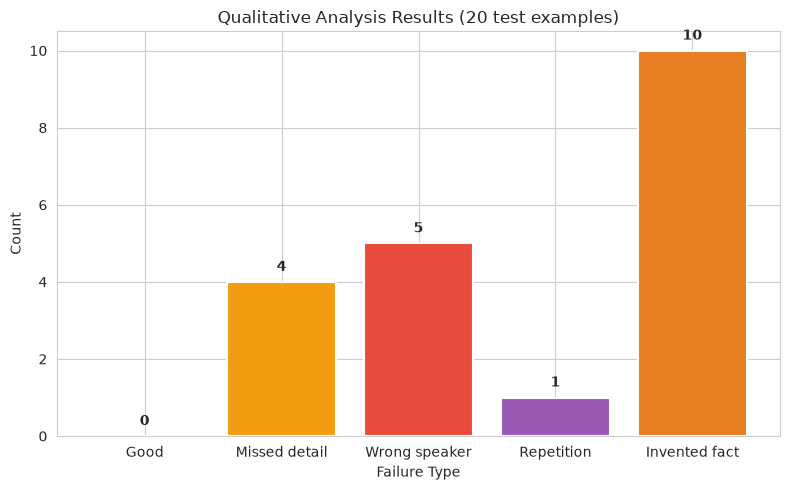

In [18]:
# Generate and tag 20 qualitative examples using the trained model
model.eval()
random.seed(SEED)
num_qual = 20
qual_indices = random.sample(range(len(test_df)), min(num_qual, len(test_df)))

# Failure categories
good = []
missed_detail = []
wrong_speaker = []
repetition = []
invented_fact = []

for i, idx in enumerate(qual_indices, 1):
    row = test_df.iloc[idx]
    encoded = encoder_tokenizer(
        row['dialogue'], return_tensors='pt',
        truncation=True, max_length=max_source_length
    ).to(device)

    with torch.no_grad():
        gen_ids = model.generate(
            **encoded, num_beams=5, length_penalty=1.0,
            no_repeat_ngram_size=3, max_length=max_target_length,
            early_stopping=True,
        )

    # Decode generated ids with the GPT-2 tokenizer, not the BERT tokenizer.
    gen_summary = decoder_tokenizer.decode(gen_ids[0], skip_special_tokens=True).strip()
    ref_summary = str(row['summary']).strip()

    gen_words = set(gen_summary.lower().split())
    ref_words = set(ref_summary.lower().split())
    dialogue_words = set(row['dialogue'].lower().split())
    has_repetition = any(
        gen_summary.lower().count(word) > 2
        for word in gen_summary.lower().split() if len(word) > 4
    )
    overlap = len(gen_words & ref_words) / max(len(ref_words), 1)
    in_dialogue = len(gen_words & dialogue_words) / max(len(gen_words), 1)

    if overlap >= 0.4 and in_dialogue >= 0.5 and not has_repetition:
        tag = 'Good'
        good.append(i)
    elif has_repetition:
        tag = 'Repetition'
        repetition.append(i)
    elif in_dialogue < 0.3:
        tag = 'Invented fact'
        invented_fact.append(i)
    elif overlap < 0.2:
        tag = 'Missed detail'
        missed_detail.append(i)
    else:
        tag = 'Wrong speaker'
        wrong_speaker.append(i)

    print(f'--- Example {i} (Tag: {tag}) ---')
    print(f'Dialogue: {row["dialogue"][:200]}...')
    print(f'Reference: {ref_summary}')
    print(f'Generated: {gen_summary}')
    print()

total = len(qual_indices)
print(f'\nFailure type summary ({total} examples):')
if total:
    print(f'  Good:              {len(good):>3} ({len(good)/total*100:.0f}%)')
    print(f'  Missed detail:     {len(missed_detail):>3} ({len(missed_detail)/total*100:.0f}%)')
    print(f'  Wrong speaker:     {len(wrong_speaker):>3} ({len(wrong_speaker)/total*100:.0f}%)')
    print(f'  Repetition:        {len(repetition):>3} ({len(repetition)/total*100:.0f}%)')
    print(f'  Invented fact:     {len(invented_fact):>3} ({len(invented_fact)/total*100:.0f}%)')

categories = ['Good', 'Missed detail', 'Wrong speaker', 'Repetition', 'Invented fact']
counts = [len(good), len(missed_detail), len(wrong_speaker), len(repetition), len(invented_fact)]
colors = ['#2ecc71', '#f39c12', '#e74c3c', '#9b59b6', '#e67e22']

plt.figure(figsize=(8, 5))
bars = plt.bar(categories, counts, color=colors, edgecolor='white', linewidth=1.5)
plt.xlabel('Failure Type')
plt.ylabel('Count')
plt.title(f'Heuristic Failure Tags ({total} test examples)')
for bar, count in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, str(count), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


### Common failure patterns

- **Missed details** — important decisions or action items may be omitted.
- **Wrong speaker attribution** — the model may associate a statement with the wrong participant.
- **Repetition** — generated phrases or ideas may repeat.
- **Invented facts** — fluent text may contain unsupported details not present in the dialogue.
- **Truncation** — long dialogues may lose context beyond the 512-token encoder limit.

The tagging above uses simple heuristics (word overlap with reference, word overlap with dialogue, repetition detection). The bar chart shows heuristic tags only — these are not manually verified failure rates. For example, "0% Good" from a heuristic does not mean zero summaries were useful; it means none met all three heuristic thresholds simultaneously. Manual review of a sample would be needed for measured rates.


In [19]:
# Save the trained model. With load_best_model_at_end=True, `model` already
# contains the best validation checkpoint restored by full_trainer.train().
FINAL_MODEL_DIR = Path('./final_model')
FINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(FINAL_MODEL_DIR)
decoder_tokenizer.save_pretrained(FINAL_MODEL_DIR)
print(f'Model and decoder tokenizer saved to {FINAL_MODEL_DIR}/')
if best_checkpoint:
    print(f'Best checkpoint restored before saving: {best_checkpoint}')
else:
    print('No best checkpoint path was recorded; saved the final in-memory model.')


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.87it/s]

Model and decoder tokenizer saved to final_model/
Best checkpoint restored before saving: ./full_run/checkpoint-3900


In [20]:
# Verify the saved best model can be reloaded and generate a summary
from transformers import AutoTokenizer, EncoderDecoderModel

loaded_model = EncoderDecoderModel.from_pretrained(FINAL_MODEL_DIR)
loaded_decoder_tok = AutoTokenizer.from_pretrained(FINAL_MODEL_DIR)
loaded_encoder_tok = AutoTokenizer.from_pretrained('bert-base-cased')
loaded_model.to(device)
loaded_model.eval()

sample = test_df.iloc[0]
encoded = loaded_encoder_tok(
    sample['dialogue'], return_tensors='pt',
    truncation=True, max_length=max_source_length
).to(device)

with torch.no_grad():
    gen_ids = loaded_model.generate(
        **encoded, num_beams=5, max_length=max_target_length,
        early_stopping=True
    )

summary = loaded_decoder_tok.decode(gen_ids[0], skip_special_tokens=True).strip()
print(f'Dialogue: {sample["dialogue"][:200]}...')
print(f'Reference: {sample["summary"]}')
print(f'Generated: {summary}')
print('Model reload and inference: SUCCESS')


Loading weights: 100%|██████████| 443/443 [00:00<00:00, 18205.73it/s]


Dialogue: Hannah: Hey, do you have Betty's number?
Amanda: Lemme check
Hannah: <file_gif>
Amanda: Sorry, can't find it.
Amanda: Ask Larry
Amanda: He called her last time we were at the park together
Hannah: I d...
Reference: Hannah needs Betty's number but Amanda doesn't have it. She needs to contact Larry.
Generated: Samantha asks Karen if she has Linda's number. Karen doesn't know Samantha. Samantha sends Samantha a link to Linda's place.
Model reload and inference: SUCCESS


## Conclusion and Next Steps

The BERT–GPT-2 encoder-decoder model was trained on the full SAMSum dataset (14,731 dialogues) with early stopping on validation ROUGE-L (patience 3, eval every 100 steps).

| Metric | Target | Validation (best, step 3900) | Test Set | Met? |
|---|---:|---:|---:|---|
| ROUGE-1 | 0.40 | 0.3173 | 0.3201 | ✗ |
| ROUGE-2 | 0.15 | 0.0935 | 0.1066 | ✗ |
| ROUGE-L | 0.35 | 0.2583 | 0.2614 | ✗ |

The model demonstrates clear learning — validation ROUGE-L improved from 0.126 to 0.258 over 4.56 epochs and beats both the extractive baseline and greedy decoding on all metrics. However, scores remain below the pitch targets. The early stopping criteria (patience 3) and single learning rate mean the architecture has not been exhaustively tested; the BERT–GPT-2 cross-attention approach may be limited for this task compared to native encoder-decoder models like BART or T5, but this requires further investigation.

### Limitations

- ROUGE measures word overlap, not meaning or factual accuracy.
- The BERT encoder truncates dialogues beyond 512 tokens, potentially losing context.
- The model may generate plausible but unsupported details (hallucination).
- Separate BERT and GPT-2 tokenizers add complexity to the preprocessing pipeline.
- The BERT–GPT-2 cross-attention architecture may be limited for this task; further testing with alternative patience settings, learning rates, and native encoder-decoder models is needed.
- Computational constraints limited the number of experiments.

### Next steps

1. Run the fallback BERT2BERT or BART-small comparison as specified in the pitch.
2. Re-train with higher early-stopping patience (8–10) and less frequent evaluation to avoid premature stopping on noisy ROUGE signals.
3. Test alternative learning rates and warmup schedules.
4. Add human evaluation for faithfulness, coverage, and conciseness.
5. Investigate speaker-aware input formatting and long-conversation handling.
6. Explore parameter-efficient fine-tuning (LoRA, QLoRA) for faster iteration.
7. Fine-tune on Acme-specific conversation data once available.
